# 📘 7.2 Ordinary Differential Equations and Initial-Value Problems

### Turning engineering rate laws into evolving system states

Notebook 7.1 estimated derivatives from sampled values. An **ordinary differential
equation (ODE)** asks the complementary question: if a physical model specifies a
state derivative, how does the state evolve?

ODEs describe many mechanical-engineering systems:

* temperature changes because energy enters, leaves and is stored;
* velocity changes because forces create acceleration;
* tank level changes because mass flows in and out;
* pressure changes because a compressible volume gains or loses fluid; and
* vibration evolves through inertia, damping and stiffness.

This notebook focuses on **formulating and interpreting** an ODE initial-value
problem. Euler and Runge-Kutta time-marching methods are reserved for Notebooks 7.3
and 7.4.


### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* identify the independent variable, state, derivative and parameters in an ODE;
* write a first-order initial-value problem in standard form;
* derive a lumped thermal ODE from an energy balance;
* interpret an ODE right-hand side as a local rate law;
* distinguish a differential equation, an initial condition and a solution;
* identify equilibrium and time scale from a first-order model;
* distinguish autonomous and non-autonomous, linear and nonlinear ODEs;
* explain the relationship between an ODE and its integral form;
* separate model, parameter, measurement and numerical errors; and
* specify the function contract later required by an ODE solver.

### 🔗 Unit Learning Outcome Alignment

This notebook supports the following MMA3001 learning outcomes:

* **LO1:** Assess the suitability and limitations of numerical analysis and machine
  learning tools for engineering applications.
* **LO2:** Demonstrate effective use of numerical analysis and machine learning tools
  to develop defensible solutions to open-ended engineering problems.
* **LO3:** Apply appropriate mathematical and numerical techniques to solve common
  engineering problems, and evaluate performance, error, stability and accuracy.

### 📚 Sources used in this notebook

* SciPy — [`scipy.integrate.solve_ivp`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html)
* SciPy User Guide — [Ordinary differential equations](https://docs.scipy.org/doc/scipy/tutorial/integrate.html#ordinary-differential-equations-solve-ivp)
* NumPy — [`numpy.gradient`](https://numpy.org/doc/stable/reference/generated/numpy.gradient.html)


## 📂 7.2.0 How to use this notebook

Run each code cell in order. No editing or input is required. Pause at each
interpretation prompt and check that you can name every quantity and its units.

> ### 🧭 Theory preface
> The equations in this notebook express familiar engineering balances. You do not
> need to memorise every analytical solution. Focus on how the ODE is assembled,
> what each symbol means, what information must be supplied, and what the model can
> and cannot claim.
>
> We use a known analytical thermal response to explore the theory. In most real
> projects, the true state trajectory and true parameters are not known; they are
> measured or inferred with uncertainty.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid
from scipy.optimize import least_squares
from scipy.signal import savgol_filter

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11})

BLUE = "#006DAE"
ORANGE = "#E57200"
GREEN = "#00843D"
RED = "#C8102E"
PURPLE = "#7A52A1"

# Baseline properties for an instrumented aluminium thermal mass.
MASS_KG = 2.0
CP_J_KG_K = 900.0
C_J_K = MASS_KG * CP_J_KG_K       # thermal capacitance, C = m*c_p
H_W_K = 7.5                       # conductance to ambient, H = h*A
AMBIENT_C = 22.0
HEATER_W = 150.0
INITIAL_C = 22.0

def thermal_rhs(time_s, temperature_c, power_w=HEATER_W,
                conductance_w_k=H_W_K, capacitance_j_k=C_J_K,
                ambient_c=AMBIENT_C):
    '''Return dT/dt [K/s] for the lumped thermal model.'''
    return (
        power_w - conductance_w_k*(temperature_c - ambient_c)
    ) / capacitance_j_k

def thermal_equilibrium(power_w=HEATER_W, conductance_w_k=H_W_K,
                        ambient_c=AMBIENT_C):
    '''Return the constant-input equilibrium temperature [°C].'''
    return ambient_c + power_w/conductance_w_k

def thermal_exact(time_s, initial_c=INITIAL_C, power_w=HEATER_W,
                  conductance_w_k=H_W_K, capacitance_j_k=C_J_K,
                  ambient_c=AMBIENT_C, initial_time_s=0.0):
    '''Exact response for constant properties, ambient and heater power.'''
    time_s = np.asarray(time_s, dtype=float)
    equilibrium_c = thermal_equilibrium(
        power_w, conductance_w_k, ambient_c
    )
    tau_s = capacitance_j_k/conductance_w_k
    return equilibrium_c + (initial_c - equilibrium_c)*np.exp(
        -(time_s-initial_time_s)/tau_s
    )

print("Setup complete: baseline thermal capacitance = "
      f"{C_J_K:.0f} J/K and time constant = {C_J_K/H_W_K:.1f} s.")


Setup complete: baseline thermal capacitance = 1800 J/K and time constant = 240.0 s.


### 📖 Core language for 7.2

| Term | Meaning |
|---|---|
| **Independent variable** $t$ | The coordinate along which the state evolves; time in this notebook |
| **State** $T(t)$ | The minimum information the model evolves; thermal-mass temperature here |
| **State derivative** $dT/dt$ | Instantaneous state-change rate [K/s] |
| **Right-hand side** $f(t,T;\boldsymbol{\theta})$ | Function that returns the derivative from time, state and parameters |
| **Parameter vector** $\boldsymbol{\theta}$ | Fixed model quantities such as $C$, $H$ and $T_\infty$ |
| **Input** $P(t)$ | A prescribed quantity that drives the model; heater power here |
| **Initial condition** $T(t_0)=T_0$ | Known state at the starting time |
| **Solution** $T(t)$ | A function that satisfies both the ODE and initial condition |

A semicolon in $f(t,T;\boldsymbol{\theta})$ visually separates variables that evolve
or are passed at each evaluation from fixed parameters. It does not change the
mathematics.


## 📂 7.2.1 What is an ordinary differential equation?

A differential equation relates an unknown function to one or more of its
derivatives. A first-order ODE can often be written as

$$
\frac{dy}{dt}=f(t,y).
$$

Here:

* $t$ is one independent variable;
* $y(t)$ is the unknown state function;
* $dy/dt$ is its first derivative; and
* $f$ is a known rate function.

It is called **ordinary** because derivatives are taken with respect to one
independent variable. A partial differential equation (PDE) includes partial
derivatives with respect to two or more independent variables, such as space and
time.

The ODE does not directly give the future value of $y$. It gives the local slope
that any valid solution must possess at each permitted $(t,y)$ pair.


## 📂 7.2.2 Engineering model: a heated thermal mass

Consider a well-mixed aluminium block with an electric heater and heat loss to a
fixed ambient environment. The **lumped** assumption treats the block as having one
spatially uniform temperature $T(t)$.

The model combines three physical statements:

1. **Energy balance:** storage rate = heater input − heat loss.
2. **Stored thermal energy:** $U=C T$, relative to a chosen reference, when thermal
   capacitance $C=m c_p$ is constant.
3. **Linear heat-loss law:** $\dot Q_{\mathrm{loss}}=H(T-T_\infty)$, where
   $H=hA$ is an overall thermal conductance.

We will substitute Statements 2 and 3 into Statement 1. No symbol is replaced without
being defined.


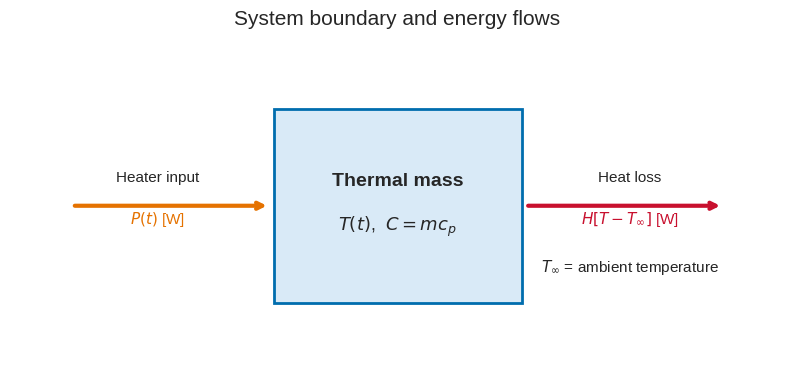

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.set_xlim(0, 10)
ax.set_ylim(0, 5)
ax.axis("off")

block = plt.Rectangle((3.4, 1.1), 3.2, 2.8, facecolor="#D9EAF7",
                      edgecolor=BLUE, linewidth=2)
ax.add_patch(block)
ax.text(5.0, 2.8, "Thermal mass", ha="center", fontsize=14, weight="bold")
ax.text(5.0, 2.15, "$T(t)$,  $C=m c_p$", ha="center", fontsize=13)

ax.annotate("", xy=(3.35, 2.5), xytext=(0.8, 2.5),
            arrowprops=dict(arrowstyle="->", lw=3, color=ORANGE))
ax.text(1.9, 2.85, "Heater input", ha="center")
ax.text(1.9, 2.25, "$P(t)$ [W]", ha="center", color=ORANGE)

ax.annotate("", xy=(9.2, 2.5), xytext=(6.65, 2.5),
            arrowprops=dict(arrowstyle="->", lw=3, color=RED))
ax.text(8.0, 2.85, "Heat loss", ha="center")
ax.text(8.0, 2.25, "$H[T-T_\\infty]$ [W]", ha="center", color=RED)
ax.text(8.0, 1.55, "$T_\\infty$ = ambient temperature", ha="center")
ax.set_title("System boundary and energy flows", fontsize=15)
plt.show()


### Combining the three statements

Start with the balance

$$
\frac{dU}{dt}=P(t)-\dot Q_{\mathrm{loss}}.
$$

Because $U=CT$ and $C$ is assumed constant,

$$
\frac{dU}{dt}=C\frac{dT}{dt}.
$$

Substitute this storage rate and $\dot Q_{\mathrm{loss}}=H(T-T_\infty)$ into the
balance:

$$
C\frac{dT}{dt}=P(t)-H(T-T_\infty).
$$

Finally divide every term by $C$ to isolate the derivative:

$$
\boxed{\frac{dT}{dt}=\frac{P(t)-H(T-T_\infty)}{C}}.
$$

This is the model's standard first-order ODE form. Temperature differences in
kelvin and degrees Celsius have the same numerical magnitude, so $T-T_\infty$ may
be calculated from temperatures reported in °C.


### Dimensional check

The numerator is a net power [W] = [J/s]. The denominator is thermal capacitance
[J/K]. Therefore

$$
\frac{P-H(T-T_\infty)}{C}
\quad\text{has units}\quad
\frac{\mathrm{J/s}}{\mathrm{J/K}}=\mathrm{K/s},
$$

which matches $dT/dt$. A unit mismatch means the rate law cannot be correct as
written, regardless of how accurately it is solved.


## 📂 7.2.3 The initial-value problem

A first-order ODE normally needs one initial state:

$$
\frac{dT}{dt}=f(t,T;\boldsymbol{\theta}),
\qquad T(t_0)=T_0.
$$

For the thermal model,

$$
f(t,T;\boldsymbol{\theta})=
\frac{P(t)-H(T-T_\infty)}{C},
\qquad
\boldsymbol{\theta}=(C,H,T_\infty).
$$

The initial condition does not add another rate law. It selects the particular
trajectory that begins at temperature $T_0$ when time is $t_0$.


In [ ]:
checks = [
    (0.0, 22.0),
    (0.0, 32.0),
    (0.0, 42.0),
    (120.0, 22.0),
]
print(" time [s]   state T [°C]   right-hand side dT/dt [K/s]")
for time_s, temperature_c in checks:
    rate = thermal_rhs(time_s, temperature_c)
    print(f" {time_s:8.1f}   {temperature_c:12.1f}   {rate:24.5f}")
print("\nThe constant-input model is autonomous, so changing time alone "
      "does not change its rate.")


 time [s]   state T [°C]   right-hand side dT/dt [K/s]
      0.0           22.0                    0.08333
      0.0           32.0                    0.04167
      0.0           42.0                    0.00000
    120.0           22.0                    0.08333

The constant-input model is autonomous, so changing time alone does not change its rate.


The function `thermal_rhs(time_s, temperature_c)` implements the ODE, not its
solution. Each call answers: **if the system were at this time and temperature, what
instantaneous rate would the model predict?**

Time remains an argument even when the current model does not use it explicitly.
This preserves the standard solver contract and allows a later input $P(t)$.


## 📂 7.2.4 Equilibrium: where the derivative is zero

An equilibrium temperature $T_{\mathrm{eq}}$ has no instantaneous change:

$$
\left.\frac{dT}{dt}\right|_{T=T_{\mathrm{eq}}}=0.
$$

For constant heater power $P$,

$$
0=P-H(T_{\mathrm{eq}}-T_\infty),
\qquad
\boxed{T_{\mathrm{eq}}=T_\infty+\frac{P}{H}}.
$$

If $T<T_{\mathrm{eq}}$, heater input exceeds heat loss and the model predicts
warming. If $T>T_{\mathrm{eq}}$, heat loss exceeds heater input and the model
predicts cooling.


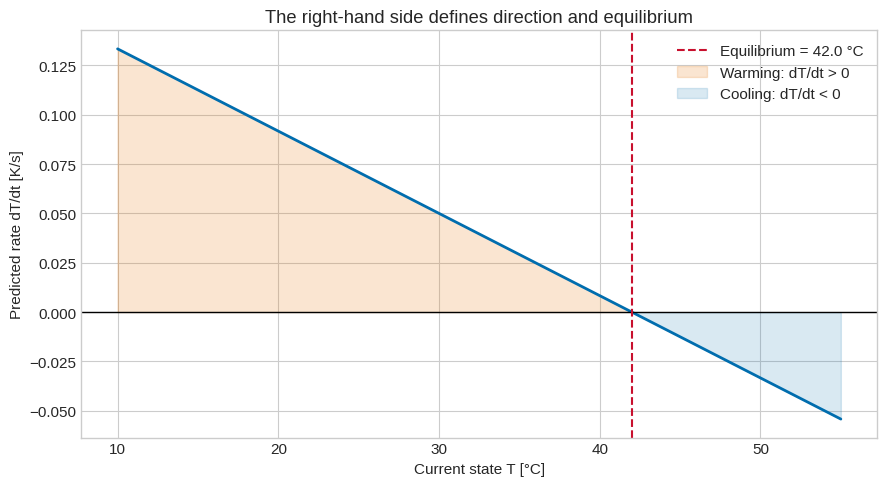

In [ ]:
temperature_axis = np.linspace(10.0, 55.0, 300)
rate_axis = thermal_rhs(0.0, temperature_axis)
equilibrium_c = thermal_equilibrium()

plt.figure(figsize=(9, 5))
plt.plot(temperature_axis, rate_axis, color=BLUE, linewidth=2)
plt.axhline(0.0, color="black", linewidth=1)
plt.axvline(equilibrium_c, color=RED, linestyle="--",
            label=f"Equilibrium = {equilibrium_c:.1f} °C")
plt.fill_between(temperature_axis, 0, rate_axis, where=rate_axis >= 0,
                 color=ORANGE, alpha=0.18, label="Warming: dT/dt > 0")
plt.fill_between(temperature_axis, 0, rate_axis, where=rate_axis < 0,
                 color=BLUE, alpha=0.15, label="Cooling: dT/dt < 0")
plt.xlabel("Current state T [°C]")
plt.ylabel("Predicted rate dT/dt [K/s]")
plt.title("The right-hand side defines direction and equilibrium")
plt.legend()
plt.tight_layout()
plt.show()


### 🧠 What should you notice?

The right-hand-side plot is not temperature versus time. Its horizontal axis is a
possible **state**, and its vertical axis is the rate predicted at that state. The
zero crossing identifies the equilibrium without solving for a full trajectory.


## 📂 7.2.5 A direction field contains many possible trajectories

For constant power and ambient temperature, the thermal ODE has the analytical
solution

$$
T(t)=T_{\mathrm{eq}}+
(T_0-T_{\mathrm{eq}})\exp\!\left[-\frac{t-t_0}{\tau}\right],
$$

where

$$
\tau=\frac{C}{H}
$$

is the thermal time constant [s]. We use this known solution to visualise ODE
concepts; later notebooks will approximate trajectories numerically when a useful
analytical solution is unavailable.


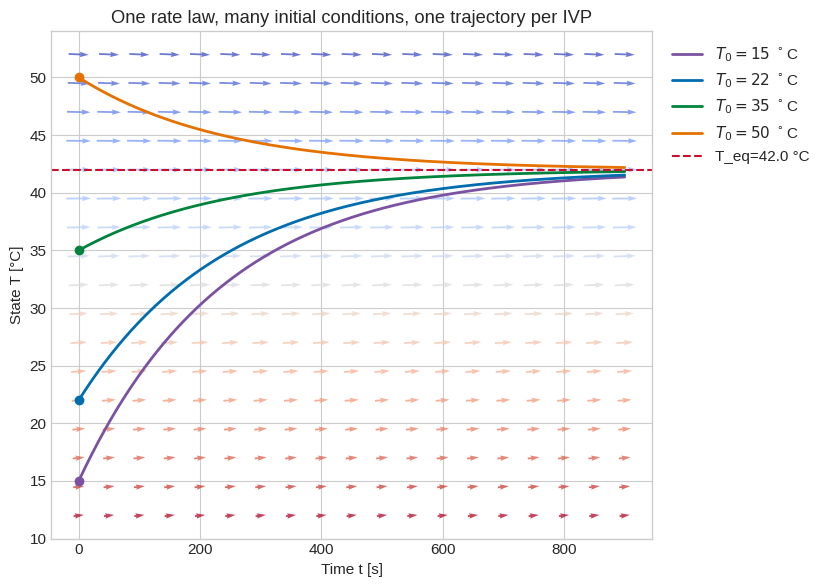

In [ ]:
field_times = np.linspace(0.0, 900.0, 19)
field_temperatures = np.linspace(12.0, 52.0, 17)
TT, YY = np.meshgrid(field_times, field_temperatures)
slopes = thermal_rhs(TT, YY)

# Direction vectors represent (dt, dT) and are normalised only for display.
dt_display = np.full_like(slopes, 60.0)
dT_display = slopes * dt_display
lengths = np.sqrt(dt_display**2 + (18*dT_display)**2)
u = dt_display/lengths
v = dT_display/lengths

plt.figure(figsize=(10, 6))
plt.quiver(TT, YY, u, v, slopes, cmap="coolwarm", pivot="mid",
           alpha=0.75, width=0.003)
t_line = np.linspace(0.0, 900.0, 500)
for initial_c, color in zip([15.0, 22.0, 35.0, 50.0],
                            [PURPLE, BLUE, GREEN, ORANGE]):
    plt.plot(t_line, thermal_exact(t_line, initial_c=initial_c),
             color=color, linewidth=2,
             label=rf"$T_0={initial_c:.0f}\ ^\circ$C")
    plt.scatter(0, initial_c, color=color, zorder=4)
plt.axhline(equilibrium_c, color=RED, linestyle="--",
            label=f"T_eq={equilibrium_c:.1f} °C")
plt.xlabel("Time t [s]")
plt.ylabel("State T [°C]")
plt.title("One rate law, many initial conditions, one trajectory per IVP")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout(rect=(0, 0, 0.84, 1))
plt.show()


### 🧠 Interpretation

Each small line segment shows the local direction supplied by the same ODE. The
coloured solution curves follow those directions. Changing $T_0$ selects a different
curve, but every curve approaches the same stable equilibrium for the same parameters
and constant input.

The displayed arrow lengths are normalised for legibility; they should not be used to
read a numerical rate. Colour and local tilt indicate the sign and relative magnitude.


## 📂 7.2.6 The initial condition is essential

The ODE alone admits a family of solutions. For constant input,

$$
T(t)=T_{\mathrm{eq}}+A\exp[-(t-t_0)/\tau]
$$

satisfies the differential equation for any constant $A$. Applying
$T(t_0)=T_0$ gives $A=T_0-T_{\mathrm{eq}}$ and selects one trajectory.

A first-order scalar ODE normally requires one scalar initial value. A second-order
displacement equation normally requires two initial values, such as initial position
and velocity; this is developed in Notebook 7.5.


## 📂 7.2.7 The time constant controls response speed

The time constant

$$
\tau=\frac{C}{H}
$$

compares the capacity to store energy with the conductance that removes it. Its units
are $(\mathrm{J/K})/(\mathrm{W/K})=\mathrm{s}$.

After one time constant, the remaining distance to equilibrium is $e^{-1}\approx
36.8\%$ of its initial value. Equivalently, a heating response has completed about
$63.2\%$ of its total temperature change.


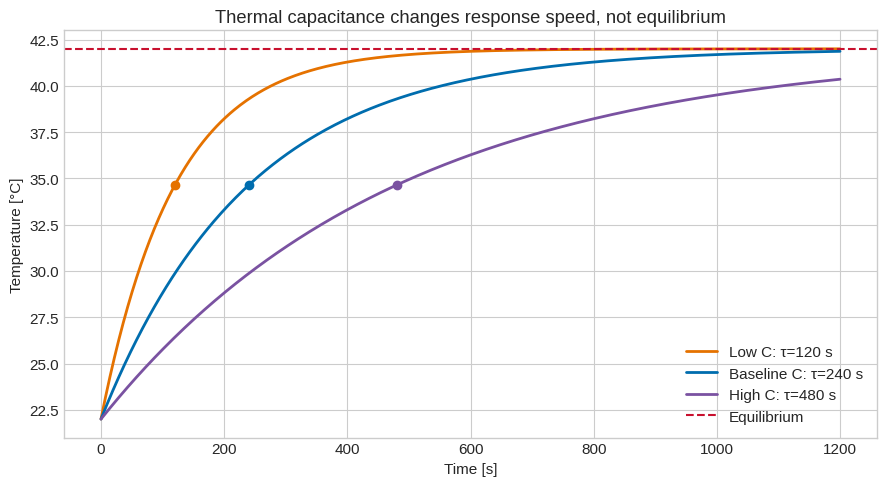

In [ ]:
time_s = np.linspace(0.0, 1200.0, 500)
cases = [
    (900.0, "Low C", ORANGE),
    (1800.0, "Baseline C", BLUE),
    (3600.0, "High C", PURPLE),
]

plt.figure(figsize=(9, 5))
for capacitance, label, color in cases:
    tau = capacitance/H_W_K
    response = thermal_exact(time_s, capacitance_j_k=capacitance)
    plt.plot(time_s, response, color=color, linewidth=2,
             label=f"{label}: τ={tau:.0f} s")
    plt.scatter(tau, thermal_exact(tau, capacitance_j_k=capacitance),
                color=color, zorder=4)
plt.axhline(equilibrium_c, color=RED, linestyle="--", label="Equilibrium")
plt.xlabel("Time [s]")
plt.ylabel("Temperature [°C]")
plt.title("Thermal capacitance changes response speed, not equilibrium")
plt.legend()
plt.tight_layout()
plt.show()


Increasing $C$ slows the response because the same net power produces a smaller
$dT/dt$. It does not change $T_{\mathrm{eq}}=T_\infty+P/H$. By contrast, changing
$H$ changes both the time constant and equilibrium. Parameter effects should be
inferred from the equations, not only from a plotted trajectory.


## 📂 7.2.8 The ODE and integral viewpoints are equivalent

Integrating the rate from $t_0$ to $t$ gives

$$
T(t)=T_0+
\int_{t_0}^{t}
\frac{P(s)-H[T(s)-T_\infty]}{C}\,ds.
$$

The symbol $s$ inside the integral is a **dummy time coordinate**. It is introduced
only to avoid using $t$ both as the integration limit and as the coordinate inside
the integral. It is not displacement and it is not a new state.

Unlike a direct Week 6 integral with a fully known integrand, this integrand depends
on the unknown temperature trajectory $T(s)$. ODE algorithms construct the state and
its accumulated change together.


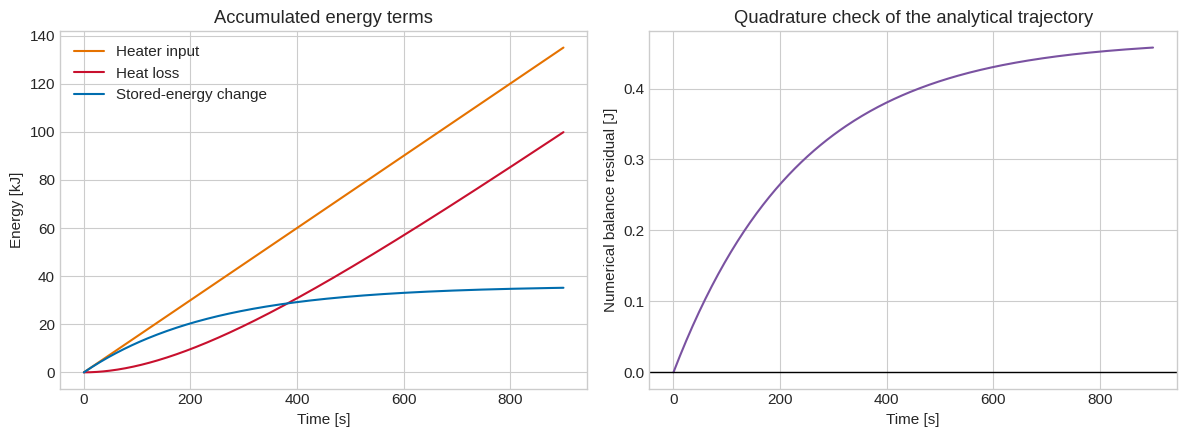

In [ ]:
t_balance = np.linspace(0.0, 900.0, 301)
temperature_balance = thermal_exact(t_balance)
input_power = np.full_like(t_balance, HEATER_W)
loss_power = H_W_K*(temperature_balance - AMBIENT_C)

input_energy = cumulative_trapezoid(input_power, t_balance, initial=0.0)
loss_energy = cumulative_trapezoid(loss_power, t_balance, initial=0.0)
net_energy_integral = input_energy - loss_energy
stored_energy_change = C_J_K*(temperature_balance - INITIAL_C)
balance_error = net_energy_integral - stored_energy_change

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(t_balance, input_energy/1000, color=ORANGE, label="Heater input")
axes[0].plot(t_balance, loss_energy/1000, color=RED, label="Heat loss")
axes[0].plot(t_balance, stored_energy_change/1000, color=BLUE,
             label="Stored-energy change")
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Energy [kJ]")
axes[0].set_title("Accumulated energy terms")
axes[0].legend()

axes[1].plot(t_balance, balance_error, color=PURPLE)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Numerical balance residual [J]")
axes[1].set_title("Quadrature check of the analytical trajectory")
fig.tight_layout()
plt.show()


The small non-zero balance residual comes from applying trapezoidal quadrature to a
finite time grid. The analytical temperature trajectory itself satisfies the
continuous balance exactly under the model assumptions.


## 📂 7.2.9 Time-dependent forcing makes the ODE non-autonomous

Suppose the heater turns off at $t_{\mathrm{off}}=600$ s:

$$
P(t)=
\begin{cases}
150\ \mathrm{W}, & t<t_{\mathrm{off}},\\
0\ \mathrm{W}, & t\ge t_{\mathrm{off}}.
\end{cases}
$$

The right-hand side now depends explicitly on time through $P(t)$, so the ODE is
**non-autonomous**. Temperature remains continuous at the switching time, while its
derivative changes immediately because the input changes.


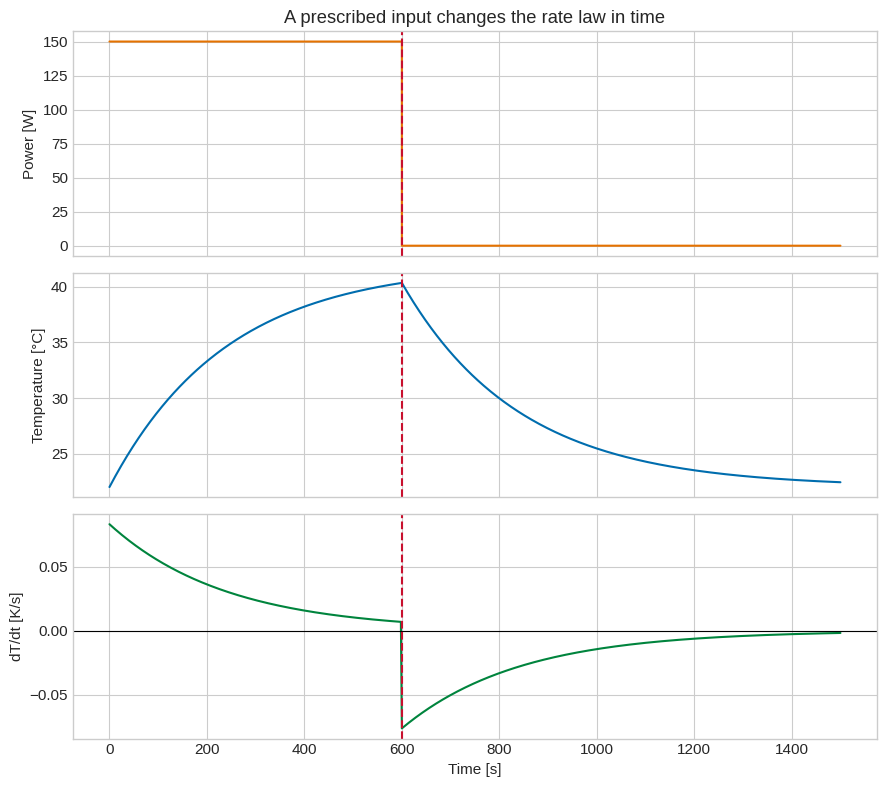

In [ ]:
switch_time_s = 600.0

def heater_schedule(time_s):
    '''Heater power [W]: on before 600 s and off afterwards.'''
    return np.where(np.asarray(time_s) < switch_time_s, HEATER_W, 0.0)

def switched_exact(time_s):
    '''Piecewise analytical temperature for the specified heater schedule.'''
    time_s = np.asarray(time_s, dtype=float)
    temperature_at_switch = thermal_exact(switch_time_s)
    heating = thermal_exact(np.minimum(time_s, switch_time_s))
    cooling = thermal_exact(
        time_s,
        initial_c=temperature_at_switch,
        power_w=0.0,
        initial_time_s=switch_time_s,
    )
    return np.where(time_s <= switch_time_s, heating, cooling)

t_switch = np.linspace(0.0, 1500.0, 751)
temperature_switch = switched_exact(t_switch)
rate_switch = thermal_rhs(
    t_switch, temperature_switch, power_w=heater_schedule(t_switch)
)

fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
axes[0].step(t_switch, heater_schedule(t_switch), where="post", color=ORANGE)
axes[0].set_ylabel("Power [W]")
axes[0].set_title("A prescribed input changes the rate law in time")
axes[1].plot(t_switch, temperature_switch, color=BLUE)
axes[1].set_ylabel("Temperature [°C]")
axes[2].plot(t_switch, rate_switch, color=GREEN)
axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set_xlabel("Time [s]")
axes[2].set_ylabel("dT/dt [K/s]")
for ax in axes:
    ax.axvline(switch_time_s, color=RED, linestyle="--")
fig.tight_layout()
plt.show()


### 🧠 State continuity versus rate discontinuity

An ideal switch creates a jump in prescribed power and therefore in $dT/dt$. It does
not create an instantaneous jump in stored thermal energy or temperature. A numerical
solver should resolve the switching time explicitly when the input definition is
discontinuous.


## 📂 7.2.10 Classifying ODE models

| Classification | Question | Example |
|---|---|---|
| **Order** | What is the highest derivative? | $dT/dt$: first order; $d^2x/dt^2$: second order |
| **Linear** | Are the state and its derivatives present only to the first power and not multiplied together? | $C\,dT/dt+HT=P+HT_\infty$ |
| **Nonlinear** | Does the rate contain nonlinear state dependence? | $m\,dv/dt=mg-cv|v|$ |
| **Autonomous** | Is there no explicit independent-variable dependence? | Constant-input thermal model |
| **Non-autonomous** | Does time appear explicitly through an input or parameter? | Thermal model with $P(t)$ |
| **Scalar** | Is there one state? | One lumped temperature $T(t)$ |
| **System** | Are several state derivatives coupled? | Two interacting thermal masses |

“Linear” describes the equation's dependence on the unknown state, not whether its
plotted solution is a straight line. The exponential thermal response comes from a
linear ODE.


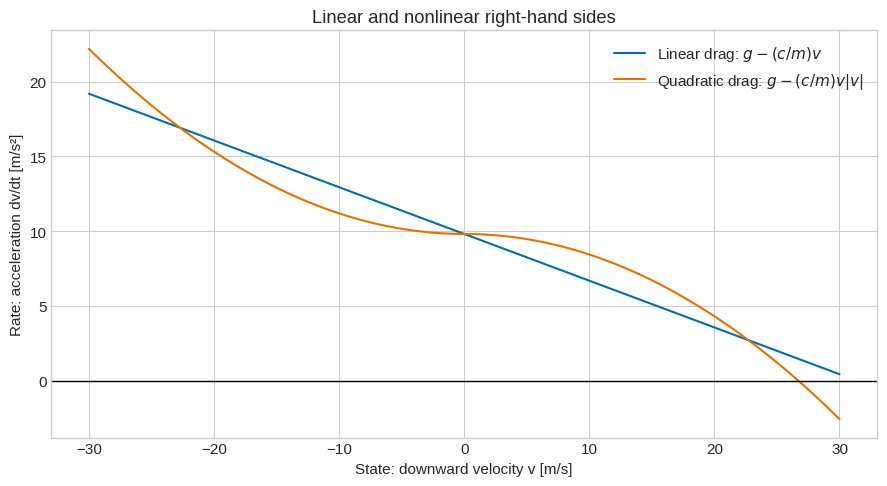

In [ ]:
velocity_axis = np.linspace(-30.0, 30.0, 500)
mass_kg = 80.0
gravity_m_s2 = 9.81
linear_drag_n_s_m = 25.0
quadratic_drag_n_s2_m2 = 1.1

linear_rate = gravity_m_s2 - linear_drag_n_s_m*velocity_axis/mass_kg
nonlinear_rate = (
    gravity_m_s2
    - quadratic_drag_n_s2_m2*velocity_axis*np.abs(velocity_axis)/mass_kg
)

plt.figure(figsize=(9, 5))
plt.plot(velocity_axis, linear_rate, color=BLUE,
         label="Linear drag: $g-(c/m)v$")
plt.plot(velocity_axis, nonlinear_rate, color=ORANGE,
         label="Quadratic drag: $g-(c/m)v|v|$")
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("State: downward velocity v [m/s]")
plt.ylabel("Rate: acceleration dv/dt [m/s²]")
plt.title("Linear and nonlinear right-hand sides")
plt.legend()
plt.tight_layout()
plt.show()


The quadratic-drag model is nonlinear because $v|v|$ is nonlinear in the state.
Both examples are autonomous when gravity and drag parameters are constant. This
classification affects the available analysis and numerical behaviour, but it does
not by itself determine whether the model is physically adequate.


## 📂 7.2.11 Initial-value problems versus boundary-value problems

An **initial-value problem (IVP)** supplies all required state information at one
starting coordinate, for example

$$
T(0)=22^\circ\mathrm{C}.
$$

A **boundary-value problem (BVP)** supplies conditions at more than one coordinate,
for example a steady rod temperature satisfying $T(0)=100^\circ$C and
$T(L)=20^\circ$C. IVPs naturally support time marching. BVPs generally require a
different solution strategy and are developed later in the unit.

Initial and boundary conditions are part of the mathematical problem, not optional
metadata attached after solving.


## 📂 7.2.12 The right-hand-side function contract

SciPy represents a first-order IVP as

```python
derivative = fun(t, y)
```

The function must return the state derivative with the same state dimension as `y`.
For one thermal state, `y` may later be passed as a one-element array rather than a
scalar. Parameters may be closed over, passed through `args`, or stored in a clear
model configuration.

The following wrapper demonstrates the shape contract without invoking a numerical
ODE solver yet.


In [ ]:
def thermal_rhs_solver(time_s, state):
    '''Solver-style wrapper: state[0] is temperature [°C].'''
    temperature_c = state[0]
    derivative_c_s = thermal_rhs(time_s, temperature_c)
    return np.array([derivative_c_s])

state_example = np.array([30.0])
derivative_example = thermal_rhs_solver(120.0, state_example)

print("State array:", state_example, "shape", state_example.shape)
print("Derivative array:", derivative_example, "shape", derivative_example.shape)
print("Meaning: at 30 °C, the model predicts "
      f"dT/dt = {derivative_example[0]:.5f} K/s.")


State array: [30.] shape (1,)
Derivative array: [0.05] shape (1,)
Meaning: at 30 °C, the model predicts dT/dt = 0.05000 K/s.


### ⚠️ State-vector warning

`state[0]` does not mean the first time sample. It means the first component of the
state vector at the current solver evaluation. For a multi-state system, `state[1]`
would represent a second physical state, not the next time step.


## 📂 7.2.13 A numerical solution is not automatically a valid model

Four distinct discrepancies can affect a model-data comparison:

1. **measurement error** in observed time or temperature;
2. **parameter error** in $C$, $H$, $P$ or $T_\infty$;
3. **model-form error** from assumptions such as a spatially uniform temperature or
   linear heat loss; and
4. **numerical error** from approximating the IVP solution.

Reducing numerical error cannot repair an incorrect parameter or missing physical
mechanism.


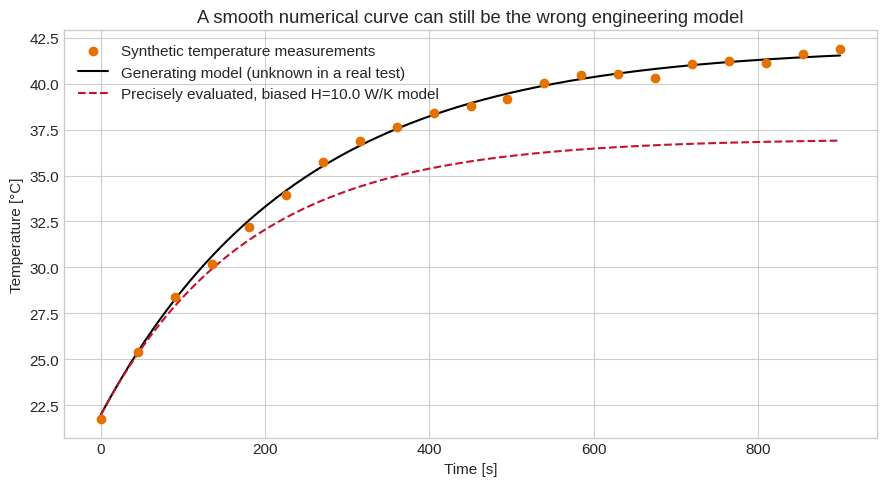

In [ ]:
rng = np.random.default_rng(72)
measurement_times = np.arange(0.0, 901.0, 45.0)
generating_temperature = thermal_exact(measurement_times)
measured_temperature = generating_temperature + rng.normal(
    0.0, 0.25, measurement_times.size
)

candidate_h = 10.0  # deliberately biased conductance
time_model = np.linspace(0.0, 900.0, 500)
candidate_temperature = thermal_exact(
    time_model, conductance_w_k=candidate_h
)

plt.figure(figsize=(9, 5))
plt.scatter(measurement_times, measured_temperature, color=ORANGE,
            label="Synthetic temperature measurements", zorder=3)
plt.plot(time_model, thermal_exact(time_model), color="black",
         label="Generating model (unknown in a real test)")
plt.plot(time_model, candidate_temperature, color=RED, linestyle="--",
         label=f"Precisely evaluated, biased H={candidate_h:.1f} W/K model")
plt.xlabel("Time [s]")
plt.ylabel("Temperature [°C]")
plt.title("A smooth numerical curve can still be the wrong engineering model")
plt.legend()
plt.tight_layout()
plt.show()


The red curve could be evaluated to many decimal places, yet it disagrees
systematically because its conductance is biased. Solver precision and model
credibility answer different questions.


## 📂 7.2.14 Residuals test the governing balance

Rearranging the energy balance defines a power residual

$$
r(t)=C\frac{dT}{dt}-\left[P(t)-H(T-T_\infty)\right].
$$

A trajectory satisfying the assumed model has $r(t)=0$. With measurements,
$dT/dt$ must be estimated and the residual is affected by the noise amplification
studied in Notebook 7.1. Residual structure can reveal model mismatch, but it must be
interpreted alongside measurement uncertainty and smoothing assumptions.


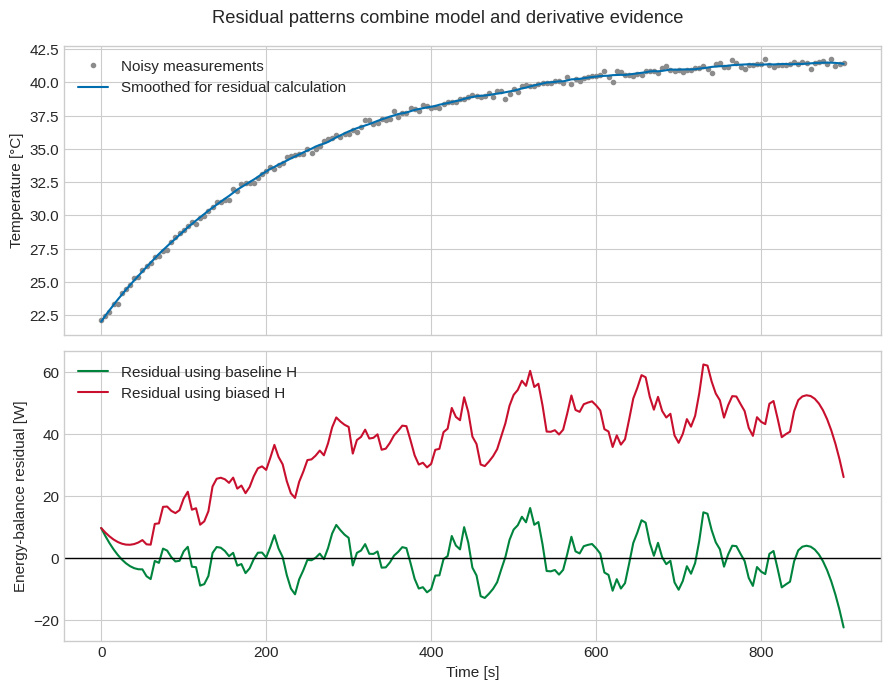

In [ ]:
dense_measurement_times = np.linspace(0.0, 900.0, 181)
true_dense_temperature = thermal_exact(dense_measurement_times)
noisy_dense_temperature = true_dense_temperature + rng.normal(
    0.0, 0.18, dense_measurement_times.size
)
dt_measurement = dense_measurement_times[1] - dense_measurement_times[0]

smooth_temperature = savgol_filter(
    noisy_dense_temperature, window_length=21, polyorder=3
)
estimated_rate = savgol_filter(
    noisy_dense_temperature, window_length=21, polyorder=3,
    deriv=1, delta=dt_measurement
)

residual_baseline = (
    C_J_K*estimated_rate
    - (HEATER_W - H_W_K*(smooth_temperature-AMBIENT_C))
)
residual_biased = (
    C_J_K*estimated_rate
    - (HEATER_W - candidate_h*(smooth_temperature-AMBIENT_C))
)

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
axes[0].plot(dense_measurement_times, noisy_dense_temperature, ".",
             color="0.55", label="Noisy measurements")
axes[0].plot(dense_measurement_times, smooth_temperature, color=BLUE,
             label="Smoothed for residual calculation")
axes[0].set_ylabel("Temperature [°C]")
axes[0].legend()

axes[1].plot(dense_measurement_times, residual_baseline, color=GREEN,
             label="Residual using baseline H")
axes[1].plot(dense_measurement_times, residual_biased, color=RED,
             label="Residual using biased H")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Energy-balance residual [W]")
axes[1].legend()
fig.suptitle("Residual patterns combine model and derivative evidence")
fig.tight_layout()
plt.show()


### ⚠️ Residual limitation

The baseline residual is not exactly zero because measurements contain noise and the
derivative uses a smoothing model. A non-zero residual does not identify one cause by
itself. Report its scale and structure, then test sensor uncertainty, parameters,
assumptions and numerical settings separately.


## 📂 7.2.15 From data points to calibrated ODE parameters

This is where an ODE model connects directly to an experimental dataset. Suppose a
test records

$$
\mathcal{D}_{\mathrm{train}}=
\{(t_i,\,P_i,\,T_{\infty,i},\,T_i^{\mathrm{meas}})\}_{i=1}^{N}.
$$

For data point $i$:

* $t_i$ is the recorded time;
* $P_i$ is the known or measured heater input;
* $T_{\infty,i}$ is the measured ambient temperature; and
* $T_i^{\mathrm{meas}}$ is the measured thermal-mass temperature.

The physics has already selected the model structure

$$
\frac{dT}{dt}=\frac{P(t)-H(T-T_\infty)}{C}.
$$

If $C$ and $H$ are uncertain, **parameter calibration**—also called parameter
estimation, system identification or training—selects values that make the model
trajectory agree with the training measurements. One least-squares objective is

$$
\widehat{\boldsymbol{\theta}}
=\underset{\boldsymbol{\theta}}{\operatorname{argmin}}
\sum_{i=1}^{N}
\left[
\frac{T_{\mathrm{model}}(t_i;\boldsymbol{\theta})
-T_i^{\mathrm{meas}}}{\sigma_T}
\right]^2,
\qquad
\boldsymbol{\theta}=(C,H).
$$

Here $\widehat{\boldsymbol{\theta}}$ denotes the fitted parameter vector and
$\sigma_T$ is a representative temperature-noise scale. The optimizer proposes
candidate parameters, the ODE model generates a trajectory at the measurement times,
and the residuals determine the next proposal.


### What is trained—and what is not?

* The **state** $T(t)$ is not one independent fitted coefficient per data point. It is
  the continuous trajectory constrained by the ODE and initial condition.
* The **parameters** $C$ and $H$ are adjusted globally so one pair explains the whole
  training experiment.
* The **inputs** $P(t)$ and $T_\infty(t)$ should normally come from measurements or a
  declared operating schedule, not be adjusted secretly to improve the fit.
* The **model structure** is chosen from physical reasoning. If the structure is
  inadequate, fitting its parameters more precisely will not repair the missing
  physics.
* The **initial condition** is often measured. It can also be estimated, but then it
  must be declared as another fitted quantity and checked for identifiability.

A fitted parameter may be an **effective parameter**. For example, fitted $H$ may
absorb convection, radiation and contact losses omitted from the one-term heat-loss
model. It should not automatically be interpreted as a direct measurement of only
one physical mechanism.


True C = 1800.0 J/K; fitted C = 1823.4 J/K
True H = 7.50 W/K; fitted H = 7.45 W/K
Training RMSE = 0.234 °C
Validation RMSE = 0.265 °C


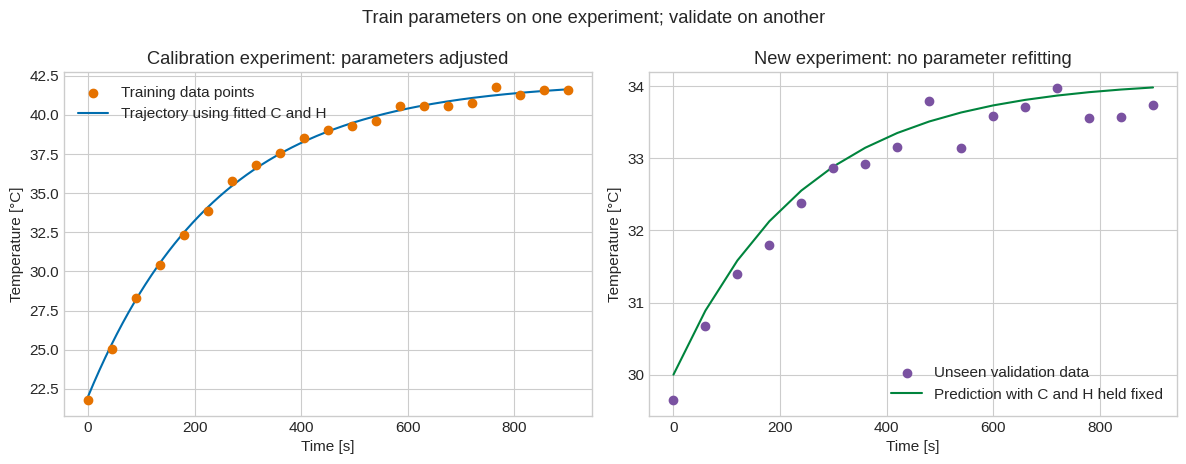

In [ ]:
# Synthetic calibration experiment: discrete temperature points under 150 W heating.
rng_calibration = np.random.default_rng(720)
temperature_noise_c = 0.25
training_times = np.arange(0.0, 901.0, 45.0)
training_temperature = thermal_exact(training_times) + rng_calibration.normal(
    0.0, temperature_noise_c, training_times.size
)

def calibration_residual(parameters):
    '''Normalised temperature residuals for candidate [C, H].'''
    capacitance_j_k, conductance_w_k = parameters
    prediction = thermal_exact(
        training_times,
        capacitance_j_k=capacitance_j_k,
        conductance_w_k=conductance_w_k,
    )
    return (prediction-training_temperature)/temperature_noise_c

fit = least_squares(
    calibration_residual,
    x0=np.array([1200.0, 11.0]),
    bounds=(np.array([300.0, 1.0]), np.array([5000.0, 30.0])),
    x_scale="jac",
)
fitted_c, fitted_h = fit.x

# Independent validation experiment: different power and initial temperature.
validation_power_w = 90.0
validation_initial_c = 30.0
validation_times = np.arange(0.0, 901.0, 60.0)
validation_temperature = thermal_exact(
    validation_times,
    initial_c=validation_initial_c,
    power_w=validation_power_w,
) + rng_calibration.normal(0.0, temperature_noise_c, validation_times.size)
validation_prediction = thermal_exact(
    validation_times,
    initial_c=validation_initial_c,
    power_w=validation_power_w,
    capacitance_j_k=fitted_c,
    conductance_w_k=fitted_h,
)

training_rmse = np.sqrt(np.mean(
    (thermal_exact(training_times, capacitance_j_k=fitted_c,
                   conductance_w_k=fitted_h)-training_temperature)**2
))
validation_rmse = np.sqrt(np.mean(
    (validation_prediction-validation_temperature)**2
))

print(f"True C = {C_J_K:.1f} J/K; fitted C = {fitted_c:.1f} J/K")
print(f"True H = {H_W_K:.2f} W/K; fitted H = {fitted_h:.2f} W/K")
print(f"Training RMSE = {training_rmse:.3f} °C")
print(f"Validation RMSE = {validation_rmse:.3f} °C")

dense_fit_time = np.linspace(0.0, 900.0, 500)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
axes[0].scatter(training_times, training_temperature, color=ORANGE,
                label="Training data points", zorder=3)
axes[0].plot(
    dense_fit_time,
    thermal_exact(dense_fit_time, capacitance_j_k=fitted_c,
                  conductance_w_k=fitted_h),
    color=BLUE, label="Trajectory using fitted C and H"
)
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Temperature [°C]")
axes[0].set_title("Calibration experiment: parameters adjusted")
axes[0].legend()

axes[1].scatter(validation_times, validation_temperature, color=PURPLE,
                label="Unseen validation data", zorder=3)
axes[1].plot(validation_times, validation_prediction, color=GREEN,
             label="Prediction with C and H held fixed")
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Temperature [°C]")
axes[1].set_title("New experiment: no parameter refitting")
axes[1].legend()
fig.suptitle("Train parameters on one experiment; validate on another")
fig.tight_layout()
plt.show()


### Identifiability depends on the collected data

A good curve fit does not guarantee that each parameter is uniquely determined.
For this model:

* the equilibrium rise $T_{\mathrm{eq}}-T_\infty=P/H$ provides information about
  $H$ when $P$ is known; and
* the transient time constant $\tau=C/H$ provides information about the ratio $C/H$.

A short test containing only the early transient may estimate $C$ reasonably from the
initial heating rate but provide weak information about $H$. A test that approaches
equilibrium, or several tests with different inputs, better separates their effects.

In a more general ODE without an analytical solution, each optimizer iteration calls
a numerical IVP solver and compares its output at the measurement times. The fitting
logic is the same, but numerical tolerances must be tight enough that solver error is
small relative to measurement noise and the parameter effects being estimated.


## 📂 7.2.16 Is the IVP completely specified?

Before selecting a numerical method, check that the model contract includes:

* the independent variable and solution interval $[t_0,t_f]$;
* every state and its physical units;
* one required initial value for each first-order state equation;
* all parameters, units and assumed constancy;
* prescribed inputs over the complete interval;
* permitted state domains and any physical constraints;
* discontinuity times or events; and
* the outputs and validation evidence needed for the engineering decision.

A solver cannot infer missing physics or an unspecified initial condition. It may
still return an array if the code supplies an accidental default, which makes model
validation and explicit contracts essential.


## 📂 7.2.17 Optional interactive thermal-response demonstration

Adjust heater power, thermal capacitance and conductance. Observe which settings
change equilibrium, which change the time constant, and which change both. All curves
use the analytical constant-input solution; no numerical ODE method is hidden here.


In [ ]:
try:
    import ipywidgets as widgets
    from IPython.display import display

    def thermal_explorer(power_w=150.0, capacitance_j_k=1800.0,
                         conductance_w_k=7.5):
        t_plot = np.linspace(0.0, 1500.0, 500)
        equilibrium = thermal_equilibrium(power_w, conductance_w_k)
        tau = capacitance_j_k/conductance_w_k
        response = thermal_exact(
            t_plot,
            power_w=power_w,
            capacitance_j_k=capacitance_j_k,
            conductance_w_k=conductance_w_k,
        )
        plt.figure(figsize=(9, 4.5))
        plt.plot(t_plot, response, color=BLUE, linewidth=2)
        plt.axhline(equilibrium, color=RED, linestyle="--",
                    label=f"Equilibrium={equilibrium:.1f} °C")
        plt.axvline(tau, color=GREEN, linestyle=":",
                    label=f"Time constant={tau:.0f} s")
        plt.xlabel("Time [s]")
        plt.ylabel("Temperature [°C]")
        plt.title("Constant-input lumped thermal response")
        plt.legend()
        plt.tight_layout()
        plt.show()

    controls = {
        "power_w": widgets.FloatSlider(
            value=150, min=0, max=300, step=25, description="Power [W]"
        ),
        "capacitance_j_k": widgets.FloatSlider(
            value=1800, min=600, max=4200, step=300, description="C [J/K]"
        ),
        "conductance_w_k": widgets.FloatSlider(
            value=7.5, min=2.5, max=15.0, step=1.25, description="H [W/K]"
        ),
    }
    output = widgets.interactive_output(thermal_explorer, controls)
    display(widgets.VBox([widgets.HBox(list(controls.values())), output]))
except ImportError:
    print("ipywidgets is unavailable; all static demonstrations remain complete.")


## 📂 7.2.18 Useful packages and functions

| Tool | Role in ODE work | Important note |
|---|---|---|
| Python function `fun(t, y)` | Encodes the right-hand side | Must return the derivative with the same state dimension |
| `np.asarray(...)` | Standardises scalar or array-like inputs | Do not confuse state dimension with time-sample dimension |
| `np.gradient(...)` | Estimates derivatives from measured trajectories | Coordinate, boundary and noise issues from 7.1 still apply |
| `cumulative_trapezoid(...)` | Checks accumulated balance terms | Numerical quadrature has its own discretisation error |
| `scipy.optimize.least_squares(...)` | Fits uncertain parameters to residuals | Use bounds, scaling and independent validation |
| `scipy.integrate.solve_ivp(...)` | Solves first-order IVPs numerically | Methods and tolerances are developed after Euler and Runge-Kutta theory |

`solve_ivp` expects `fun(t, y)`, a time interval and an initial state. Calling a
package routine is not a substitute for defining those quantities and their units.


## 📂 7.2.19 Engineering workflow and summary

### Formulation workflow

1. Draw the system boundary and identify storage, inputs and outputs.
2. Write the governing balance before substituting constitutive laws.
3. Define every state, parameter, input and unit.
4. Isolate the highest derivative to create the right-hand side.
5. State the initial condition and solution interval.
6. Check dimensions, derivative signs, equilibrium and limiting behaviour.
7. Implement `fun(t, y)` and test it at interpretable states.
8. If parameters are uncertain, calibrate them on informative training data.
9. Hold fitted parameters fixed and test predictions on an independent experiment.
10. Separate model and parameter validation from numerical-method validation.

### Key definitions

* An ODE relates an unknown state function to derivatives with respect to one
  independent variable.
* An IVP combines the ODE with all required state information at one starting point.
* The right-hand side supplies a local derivative, not a future state.
* Equilibrium occurs where the state derivative is zero.
* A time constant characterises the response scale of this stable first-order model.

### Method review

The thermal example combined conservation of energy, constant thermal capacitance
and a linear heat-loss law. The resulting ODE was interpreted through its rate-state
plot, direction field, exact solution, equilibrium, time constant, integral balance,
prescribed input, residual and data-driven parameter calibration. No time-marching
numerical method has yet been used.


## 🔗 Bridge to Notebook 7.3

The thermal IVP is now fully specified:

$$
\frac{dT}{dt}=f(t,T),\qquad T(t_0)=T_0.
$$

Notebook 7.3 will construct Euler's method by using the current right-hand-side value
as a local slope over a finite time step. We will compare that approximation with the
analytical thermal trajectory, distinguish local and global error, and test the
effects of step size and stability.


## 📚 References

1. SciPy Developers, [`scipy.integrate.solve_ivp`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html), accessed 2026.
2. SciPy Developers, [Ordinary differential equations](https://docs.scipy.org/doc/scipy/tutorial/integrate.html#ordinary-differential-equations-solve-ivp), accessed 2026.
3. NumPy Developers, [`numpy.gradient`](https://numpy.org/doc/stable/reference/generated/numpy.gradient.html), accessed 2026.
